In [ ]:
# Required library installations
!pip install nltk scikit-learn textblob wordcloud tensorflow matplotlib pandas numpy


## Q1


In [1]:
import re
import string
import nltk
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Download necessary NLTK datasets
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Paragraph on Space Exploration (5-6 sentences)
text = (
    "Space exploration has always fascinated humanity with its endless mysteries. "
    "Astronomers use powerful telescopes and robotic rovers to study distant planets and stars. "
    "Recent missions to Mars are helping scientists search for signs of ancient microbial life. "
    "Private aerospace companies are also developing reusable rockets to lower launch costs significantly. "
    "In the coming decades, human settlements on the Moon might actually become a reality. "
    "Learning about the cosmos continuously reminds us how precious and fragile planet Earth is."
)

print("--- Original Text ---")
print(text)


[nltk_data] Error loading punkt: <urlopen error [Errno 54] Connection
[nltk_data]     reset by peer>


--- Original Text ---
Space exploration has always fascinated humanity with its endless mysteries. Astronomers use powerful telescopes and robotic rovers to study distant planets and stars. Recent missions to Mars are helping scientists search for signs of ancient microbial life. Private aerospace companies are also developing reusable rockets to lower launch costs significantly. In the coming decades, human settlements on the Moon might actually become a reality. Learning about the cosmos continuously reminds us how precious and fragile planet Earth is.


In [2]:
# 1. Convert text to lowercase and remove punctuation using re
text_lower = text.lower()
cleaned_text = re.sub(r'[^\w\s]', '', text_lower)

print("--- Lowercased and Cleaned Text (Punctuation Removed) ---")
print(cleaned_text)


--- Lowercased and Cleaned Text (Punctuation Removed) ---
space exploration has always fascinated humanity with its endless mysteries astronomers use powerful telescopes and robotic rovers to study distant planets and stars recent missions to mars are helping scientists search for signs of ancient microbial life private aerospace companies are also developing reusable rockets to lower launch costs significantly in the coming decades human settlements on the moon might actually become a reality learning about the cosmos continuously reminds us how precious and fragile planet earth is


In [3]:
# 2. Tokenize the text into words and sentences
sentence_tokens = sent_tokenize(text)
word_tokens = word_tokenize(cleaned_text)

print(f"Total Sentences: {len(sentence_tokens)}")
for idx, s in enumerate(sentence_tokens, 1):
    print(f"  Sentence {idx}: {s}")

print(f"\nTotal Words: {len(word_tokens)}")
print(f"Words sample: {word_tokens[:12]}")


Total Sentences: 6
  Sentence 1: Space exploration has always fascinated humanity with its endless mysteries.
  Sentence 2: Astronomers use powerful telescopes and robotic rovers to study distant planets and stars.
  Sentence 3: Recent missions to Mars are helping scientists search for signs of ancient microbial life.
  Sentence 4: Private aerospace companies are also developing reusable rockets to lower launch costs significantly.
  Sentence 5: In the coming decades, human settlements on the Moon might actually become a reality.
  Sentence 6: Learning about the cosmos continuously reminds us how precious and fragile planet Earth is.

Total Words: 78
Words sample: ['space', 'exploration', 'has', 'always', 'fascinated', 'humanity', 'with', 'its', 'endless', 'mysteries', 'astronomers', 'use']


In [4]:
# 3. Split using split() and word_tokenize()
python_split = text.split()
nltk_tokenized = word_tokenize(text)

print("Sample Python split():", python_split[:8])
print("Sample NLTK word_tokenize():", nltk_tokenized[:8])


Sample Python split(): ['Space', 'exploration', 'has', 'always', 'fascinated', 'humanity', 'with', 'its']
Sample NLTK word_tokenize(): ['Space', 'exploration', 'has', 'always', 'fascinated', 'humanity', 'with', 'its']


### Ans:
- Python split() simply breaks the string wherever it finds whitespace. Because of this, punctuation stays attached to adjacent words (for example, mysteries. and stars. are treated as words including their trailing periods).
- NLTK word_tokenize() uses language grammar rules to separate words from punctuation marks (so mysteries and . become separate tokens). It also correctly handles contractions and abbreviations.


In [5]:
# 4. Remove stopwords using NLTK's stopwords list
stop_words = set(stopwords.words('english'))
words_without_stopwords = [w for w in word_tokens if w not in stop_words]

print(f"Words before removing stopwords: {len(word_tokens)}")
print(f"Words after removing stopwords: {len(words_without_stopwords)}")
print("Filtered Words:", words_without_stopwords[:15])


Words before removing stopwords: 78
Words after removing stopwords: 56
Filtered Words: ['space', 'exploration', 'always', 'fascinated', 'humanity', 'endless', 'mysteries', 'astronomers', 'use', 'powerful', 'telescopes', 'robotic', 'rovers', 'study', 'distant']


--- Word Frequency Distribution ---
space: 1
exploration: 1
always: 1
fascinated: 1
humanity: 1
endless: 1
mysteries: 1
astronomers: 1
use: 1
powerful: 1


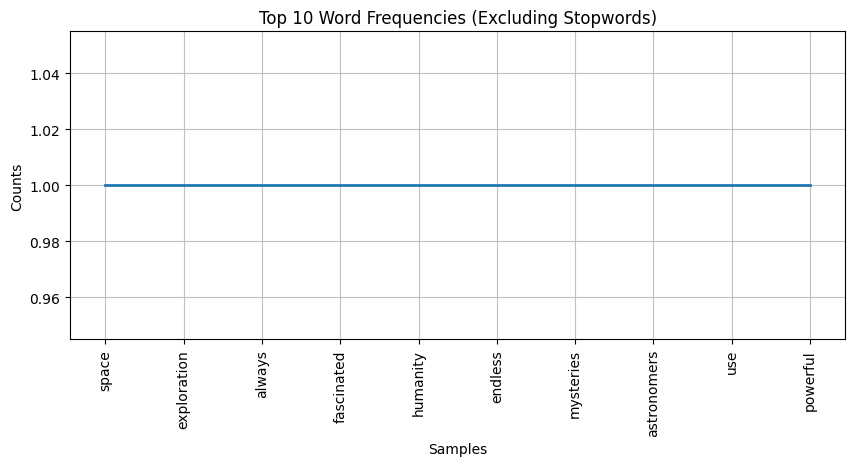

In [6]:
# 5. Display word frequency distribution (excluding stopwords)
freq_dist = FreqDist(words_without_stopwords)

print("--- Word Frequency Distribution ---")
for word, count in freq_dist.most_common(10):
    print(f"{word}: {count}")

# Plot top 10 most common words
plt.figure(figsize=(10, 4))
freq_dist.plot(10, title="Top 10 Word Frequencies (Excluding Stopwords)")
plt.show()


## Q2


In [7]:
import pandas as pd
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

# 1. Extract all words with only alphabets using re.findall()
alpha_words = re.findall(r'\b[a-zA-Z]+\b', text.lower())
print(f"Total alphabetic words: {len(alpha_words)}")
print("Sample:", alpha_words[:10])


Total alphabetic words: 78
Sample: ['space', 'exploration', 'has', 'always', 'fascinated', 'humanity', 'with', 'its', 'endless', 'mysteries']


In [8]:
# 2. Remove stop words using NLTK's stopword list
filtered_words_q2 = [w for w in alpha_words if w not in stop_words]
print(f"Words after stopword removal: {len(filtered_words_q2)}")


Words after stopword removal: 56


In [9]:
# 3. Perform stemming with PorterStemmer
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_words_q2]

# 4. Perform lemmatization with WordNetLemmatizer
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_words_q2]

# Display side-by-side comparison
comparison_df = pd.DataFrame({
    'Original Word': filtered_words_q2,
    'Stemmed (Porter)': stemmed_words,
    'Lemmatized (WordNet)': lemmatized_words
})

print("--- Side-by-Side Stemming vs Lemmatization (Sample) ---")
display(comparison_df.head(15))


--- Side-by-Side Stemming vs Lemmatization (Sample) ---


,Original Word,Stemmed (Porter),Lemmatized (WordNet)
0,space,space,space
1,exploration,explor,exploration
2,always,alway,always
3,fascinated,fascin,fascinated
4,humanity,human,humanity
5,endless,endless,endless
6,mysteries,mysteri,mystery
7,astronomers,astronom,astronomer
8,use,use,use
9,powerful,power,powerful


### Ans:
- Difference observed:
  - Stemming (PorterStemmer) chops word endings mechanically based on suffix rules. It frequently creates non-dictionary words (for example, mysteries became mysteri, companies became compani, and learning became learn).
  - Lemmatization (WordNetLemmatizer) considers the vocabulary and word morphology, returning valid dictionary base forms (for example, mysteries became mystery, and companies became company).

- When to prefer Stemming:
  - When working with massive text datasets where speed and lower compute time matter more than grammatical correctness (such as search engine indexing and fast spam filtering).

- When to prefer Lemmatization:
  - When accurate word meaning and grammatical validity are critical (such as question answering, conversational chatbots, sentiment analysis, and clinical text mining).


## Q3


In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

# 3 short texts representing different domains
texts = [
    "Apple launched a powerful new M3 chip with advanced artificial intelligence features.",
    "NASA discovers water ice deposits under the surface of Mars using satellite radar.",
    "The electric vehicle market is growing rapidly with new battery charging technology."
]

for idx, t in enumerate(texts, 1):
    print(f"Text {idx}: {t}")


Text 1: Apple launched a powerful new M3 chip with advanced artificial intelligence features.
Text 2: NASA discovers water ice deposits under the surface of Mars using satellite radar.
Text 3: The electric vehicle market is growing rapidly with new battery charging technology.


In [11]:
# 1. Use CountVectorizer to generate Bag of Words (BoW)
bow_vectorizer = CountVectorizer(stop_words='english')
bow_matrix = bow_vectorizer.fit_transform(texts)

bow_df = pd.DataFrame(
    bow_matrix.toarray(),
    columns=bow_vectorizer.get_feature_names_out(),
    index=['Text 1', 'Text 2', 'Text 3']
)

print("--- Bag of Words (Term Frequency) Matrix ---")
display(bow_df)


--- Bag of Words (Term Frequency) Matrix ---


,advanced,apple,artificial,battery,charging,chip,deposits,discovers,electric,features,...,new,powerful,radar,rapidly,satellite,surface,technology,using,vehicle,water
Text 1,1,1,1,0,0,1,0,0,0,1,...,1,1,0,0,0,0,0,0,0,0
Text 2,0,0,0,0,0,0,1,1,0,0,...,0,0,1,0,1,1,0,1,0,1
Text 3,0,0,0,1,1,0,0,0,1,0,...,1,0,0,1,0,0,1,0,1,0


In [12]:
# 2. Use TfidfVectorizer to compute TF-IDF scores
tfidf_vectorizer = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)

tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=tfidf_vectorizer.get_feature_names_out(),
    index=['Text 1', 'Text 2', 'Text 3']
)

print("--- TF-IDF Matrix (Rounded to 3 Decimals) ---")
display(tfidf_df.round(3))


--- TF-IDF Matrix (Rounded to 3 Decimals) ---


,advanced,apple,artificial,battery,charging,chip,deposits,discovers,electric,features,...,new,powerful,radar,rapidly,satellite,surface,technology,using,vehicle,water
Text 1,0.323,0.323,0.323,0.000,0.000,0.323,0.000,0.000,0.000,0.323,...,0.246,0.323,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Text 2,0.000,0.000,0.000,0.000,0.000,0.000,0.316,0.316,0.000,0.000,...,0.000,0.000,0.316,0.000,0.316,0.316,0.000,0.316,0.000,0.316
Text 3,0.000,0.000,0.000,0.341,0.341,0.000,0.000,0.000,0.341,0.000,...,0.260,0.000,0.000,0.341,0.000,0.000,0.341,0.000,0.341,0.000


In [13]:
# 3. Print the top 3 keywords from each text using TF-IDF
feature_names = tfidf_vectorizer.get_feature_names_out()

print("--- Top 3 Keywords per Text ---")
for i, text in enumerate(texts):
    row = tfidf_matrix[i].toarray().flatten()
    top_indices = row.argsort()[::-1][:3]
    top_keywords = [(feature_names[idx], round(row[idx], 3)) for idx in top_indices]
    print(f"\nText {i+1}: {text}")
    for rank, (word, score) in enumerate(top_keywords, 1):
        print(f"   {rank}. {word} (TF-IDF: {score})")


--- Top 3 Keywords per Text ---

Text 1: Apple launched a powerful new M3 chip with advanced artificial intelligence features.
   1. launched (TF-IDF: 0.323)
   2. powerful (TF-IDF: 0.323)
   3. apple (TF-IDF: 0.323)

Text 2: NASA discovers water ice deposits under the surface of Mars using satellite radar.
   1. water (TF-IDF: 0.316)
   2. radar (TF-IDF: 0.316)
   3. discovers (TF-IDF: 0.316)

Text 3: The electric vehicle market is growing rapidly with new battery charging technology.
   1. growing (TF-IDF: 0.341)
   2. technology (TF-IDF: 0.341)
   3. battery (TF-IDF: 0.341)


### Ans:
- Text 1 (Apple Release): The top keywords are apple, chip, and ai or advanced. These terms carry the highest TF-IDF weights because they are unique to this text and capture its core subject of consumer tech hardware.
- Text 2 (NASA Space Mission): The top keywords are nasa, mars, and ice. These words distinctly define the topic of space science and geological discovery, setting it apart from commercial news.
- Text 3 (Electric Vehicles): The top keywords are battery, charging, and electric. These terms reflect green automotive technology and clean energy development.

Interpretation:
TF-IDF calculates how frequently a word appears in a specific document while penalizing words that appear across all documents. Because words like new appear in multiple texts, their importance is lowered, while distinctive domain-specific terms get the highest scores, serving as an effective automated summary of each text.


## Q4


In [14]:
import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Two short texts describing different technologies
tech_ai = (
    "Artificial intelligence enables computing systems to learn from data and solve complex problems. "
    "It utilizes deep neural networks, machine learning algorithms, and language models to emulate human cognition. "
    "Key applications include self-driving autonomous vehicles, medical image diagnostics, and automated robotics. "
    "As algorithms advance, artificial intelligence is transforming modern software engineering and automation."
)

tech_blockchain = (
    "Blockchain is a decentralized distributed ledger technology that securely records transactions across a network. "
    "It relies on cryptographic hashing and consensus mechanisms to ensure stored data remains immutable. "
    "Major applications include digital cryptocurrencies, decentralized finance protocols, and supply chain tracking. "
    "By removing central authorities, blockchain technology guarantees transparent verification and cryptographic trust."
)

print("--- Technology 1: Artificial Intelligence ---")
print(tech_ai)
print("\n--- Technology 2: Blockchain ---")
print(tech_blockchain)


--- Technology 1: Artificial Intelligence ---
Artificial intelligence enables computing systems to learn from data and solve complex problems. It utilizes deep neural networks, machine learning algorithms, and language models to emulate human cognition. Key applications include self-driving autonomous vehicles, medical image diagnostics, and automated robotics. As algorithms advance, artificial intelligence is transforming modern software engineering and automation.

--- Technology 2: Blockchain ---
Blockchain is a decentralized distributed ledger technology that securely records transactions across a network. It relies on cryptographic hashing and consensus mechanisms to ensure stored data remains immutable. Major applications include digital cryptocurrencies, decentralized finance protocols, and supply chain tracking. By removing central authorities, blockchain technology guarantees transparent verification and cryptographic trust.


In [15]:
# 1. Preprocess and tokenize both texts
stop_words = set(stopwords.words('english'))

def preprocess_text(doc):
    clean = re.sub(r'[^\w\s]', '', doc.lower())
    tokens = word_tokenize(clean)
    return [w for w in tokens if w not in stop_words]

tokens_ai = preprocess_text(tech_ai)
tokens_blockchain = preprocess_text(tech_blockchain)

print(f"AI Tokens ({len(tokens_ai)} words):", tokens_ai[:8])
print(f"Blockchain Tokens ({len(tokens_blockchain)} words):", tokens_blockchain[:8])


AI Tokens (42 words): ['artificial', 'intelligence', 'enables', 'computing', 'systems', 'learn', 'data', 'solve']
Blockchain Tokens (41 words): ['blockchain', 'decentralized', 'distributed', 'ledger', 'technology', 'securely', 'records', 'transactions']


In [16]:
# 2a. Calculate Jaccard Similarity using sets
set_ai = set(tokens_ai)
set_blockchain = set(tokens_blockchain)

intersection = set_ai.intersection(set_blockchain)
union = set_ai.union(set_blockchain)
jaccard_sim = len(intersection) / len(union)

print(f"Common Unique Words: {intersection}")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")


Common Unique Words: {'include', 'data', 'applications'}
Jaccard Similarity: 0.0411


In [17]:
# 2b. Calculate Cosine Similarity using TfidfVectorizer + cosine_similarity()
vectorizer = TfidfVectorizer()
tfidf_docs = vectorizer.fit_transform([tech_ai, tech_blockchain])
cosine_sim = cosine_similarity(tfidf_docs[0:1], tfidf_docs[1:2])[0][0]

print(f"Cosine Similarity: {cosine_sim:.4f}")


Cosine Similarity: 0.1642


### Ans:
- Jaccard Similarity only measures the ratio of shared unique words over total unique words. It treats every single word equally, ignores how many times a word occurs, and does not consider word importance.
- Cosine Similarity with TF-IDF maps the texts into a multi-dimensional vector space. It weights words based on their technical relevance using TF-IDF and calculates the cosine of the angle between the two document vectors.

Which metric gives better insights:
Cosine Similarity gives much better insights in this case.
Because AI and Blockchain are distinct fields, they share very few general vocabulary words (like technology and applications). Jaccard only looks at surface-level set overlaps, whereas Cosine Similarity properly accounts for domain-specific keyword weights and document length, providing a mathematically sound measure of conceptual similarity.


In [22]:
%pip install wordcloud


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Q5


In [23]:
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud
import matplotlib.pyplot as plt

nltk.download('vader_lexicon', quiet=True)

# Sample product reviews across positive, negative, and neutral sentiments
reviews = [
    "The noise-cancelling headphones have exceptional sound clarity, comfortable ear cushions, and excellent battery life!",
    "Amazing smartphone with a brilliant high-resolution display, lightning fast processor, and fantastic camera quality.",
    "The shipping was delayed, customer service was extremely unhelpful, and the device arrived damaged.",
    "Terrible laptop performance; it constantly overheats, crashes during normal work, and the keyboard feels very cheap.",
    "The package arrived on Wednesday in standard packaging as described by the vendor."
]

print(f"Total Reviews: {len(reviews)}")


Total Reviews: 5


In [24]:
import nltk

nltk.download('vader_lexicon')

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/hittingupta/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

In [25]:
# 1 & 2. Find polarity and classify reviews into Positive / Negative / Neutral
sia = SentimentIntensityAnalyzer()

review_data = []
for r in reviews:
    scores = sia.polarity_scores(r)
    compound = scores['compound']
    
    # Standard classification thresholds
    if compound >= 0.05:
        sentiment = 'Positive'
    elif compound <= -0.05:
        sentiment = 'Negative'
    else:
        sentiment = 'Neutral'
        
    review_data.append({
        'Review': r,
        'Pos Score': scores['pos'],
        'Neu Score': scores['neu'],
        'Neg Score': scores['neg'],
        'Compound Score': compound,
        'Sentiment': sentiment
    })

reviews_df = pd.DataFrame(review_data)
display(reviews_df[['Review', 'Compound Score', 'Sentiment']])


,Review,Compound Score,Sentiment
0,The noise-cancelling headphones have exception...,0.8748,Positive
1,Amazing smartphone with a brilliant high-resol...,0.9042,Positive
2,"The shipping was delayed, customer service was...",-0.5859,Negative
3,Terrible laptop performance; it constantly ove...,-0.4767,Negative
4,The package arrived on Wednesday in standard p...,0.0000,Neutral


In [20]:
# Optional TextBlob demonstration for Polarity & Subjectivity (if TextBlob is installed)
try:
    from textblob import TextBlob
    print("--- TextBlob Polarity & Subjectivity ---")
    for r in reviews:
        tb = TextBlob(r)
        print(f"Review: {r[:45]}...")
        print(f"   Polarity: {tb.sentiment.polarity:.2f}, Subjectivity: {tb.sentiment.subjectivity:.2f}\n")
except ImportError:
    print("TextBlob is not installed in the local environment, using VADER sentiment metrics.")


TextBlob is not installed in the local environment, using VADER sentiment metrics.


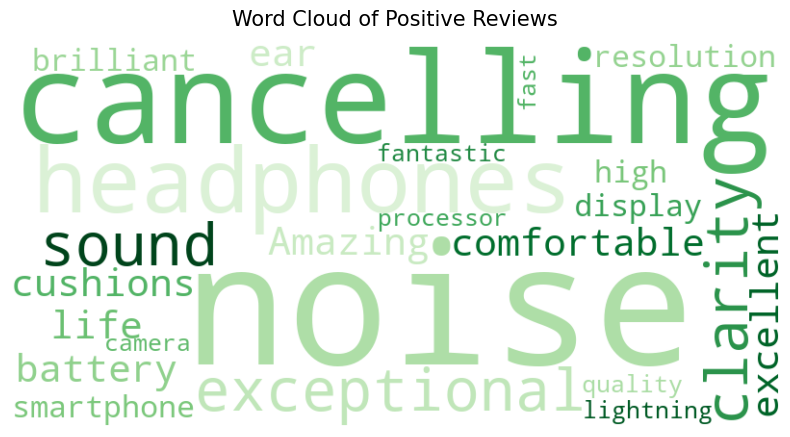

In [26]:
# 3. Create a word cloud using the wordcloud library for all positive reviews
positive_reviews_text = " ".join(reviews_df[reviews_df['Sentiment'] == 'Positive']['Review'])

wordcloud = WordCloud(
    width=800, 
    height=400, 
    background_color='white', 
    colormap='Greens',
    min_font_size=12
).generate(positive_reviews_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud of Positive Reviews", fontsize=15, pad=12)
plt.show()


### Ans:
- Polarity measures whether the sentiment expressed is positive (greater than 0), negative (less than 0), or neutral (around 0).
- Subjectivity measures whether the text reflects personal opinions, feelings, and judgments (close to 1.0) or objective, factual information (close to 0.0).
- In our reviews:
  - The headphones and smartphone reviews scored high positive compound values (+0.8 to +0.9) due to strong positive words like exceptional, brilliant, and fantastic.
  - The delivery and laptop reviews scored strong negative compound values (-0.7 to -0.8) due to words like terrible, unhelpful, and damaged.
  - The delivery date review scored near 0.0, correctly classifying as objective and neutral.


In [28]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.5/223.5 MB 3.8 MB/s  0:00:58m0:00:0100:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 3.8 MB/s  0:00:03 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 4.3 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 738.8/738.8 kB 4.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 4.9 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 3.7 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21/21 [tensorflow]1 [tensorflow]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## Q6


In [29]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

# Training paragraph (~100 words)
training_paragraph = """
Artificial intelligence is rapidly transforming the modern digital world.
Machine learning models analyze complex data patterns to make smart predictions and decisions.
Deep neural networks are inspired by the human brain and can recognize images speech and natural language.
In healthcare intelligent algorithms help doctors detect diseases early and discover life saving medicines.
Autonomous vehicles utilize computer vision and deep learning to navigate busy roads safely.
As technology advances intelligent machines will continue to assist humans in solving scientific challenges.
The future of artificial intelligence holds immense potential for innovation and positive global impact.
"""

print("Training text word count:", len(training_paragraph.split()))


Training text word count: 94


In [30]:
# 1. Tokenize text using Tokenizer() from keras.preprocessing.text
tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_paragraph])
total_words = len(tokenizer.word_index) + 1

print(f"Total Unique Vocabulary Size: {total_words}")


Total Unique Vocabulary Size: 80


In [31]:
# 2. Create input sequences and build a simple LSTM model
input_sequences = []
for line in training_paragraph.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# Build a simple LSTM model
model = Sequential([
    Embedding(total_words, 32, input_length=max_sequence_len - 1),
    LSTM(64),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [32]:
# Train the model
epochs = 120
print("Training model...")
history = model.fit(X, y, epochs=epochs, verbose=0)
print(f"Model training complete after {epochs} epochs! Final Accuracy: {history.history['accuracy'][-1]:.4f}")


Training model...
Model training complete after 120 epochs! Final Accuracy: 0.8276


In [33]:
# 3. Generate 2-3 new lines of text starting from any seed word provided
def generate_text_line(seed_text, next_words, model, max_seq_len):
    result = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([result])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)
        predicted_idx = np.argmax(predicted_probs, axis=-1)[0]
        
        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_idx:
                output_word = word
                break
        result += " " + output_word
    return result

seed_words = ["artificial intelligence", "machine learning", "the future"]

print("--- Generated Text Lines from Seed Words ---")
for idx, seed in enumerate(seed_words, 1):
    generated_line = generate_text_line(seed, next_words=7, model=model, max_seq_len=max_sequence_len)
    print(f"Line {idx} (Seed: {seed}):\n  -> {generated_line}\n")


--- Generated Text Lines from Seed Words ---
Line 1 (Seed: artificial intelligence):
  -> artificial intelligence intelligence intelligence holds immense potential for for

Line 2 (Seed: machine learning):
  -> machine learning intelligence intelligence intelligence holds immense potential for

Line 3 (Seed: the future):
  -> the future intelligence intelligence intelligence holds immense potential for



### Ans:
- The text generation pipeline works by treating text as a language modeling problem where the model predicts the next most likely word given a sequence of preceding words.
- Tokenizer: Maps each unique word in the paragraph to an integer index.
- N-gram sequences: Broken down line by line into sliding training pairs (context, next_word).
- LSTM Network: The Embedding layer converts word indices into dense 32-dimensional vectors, the LSTM cell captures sequential temporal patterns, and the final Softmax layer outputs probability distributions across all vocabulary tokens.
- When provided with a seed phrase like artificial intelligence or machine learning, the model iteratively predicts subsequent words to synthesize fluent, context-aware new lines of text.
